In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

from typing import Final

from numpy import set_printoptions
from sklearn import set_config

from csm500_project import preprocess_planning_data, preprocess_aggregate_geodata, discrete_data_analysis, \
    text_data_analysis, correlation_analysis, continuous_data_analysis
from csm500_project.constant import INFERRED_TARGET_FIELD
from csm500_project.geospatial import preprocess_heritage_data, preprocess_environmental_data, preprocess_physical_data, \
    preprocess_administrative_data

set_config(display="diagram", transform_output="pandas")
set_printoptions(precision=2, linewidth=250)

print("---Preprocessing Output---")
df = preprocess_planning_data()
print(df.head())
print("--------------------------")


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---Preprocessing Output---
Raw shape: (100627, 8)
Raw Null Values:
 entry-date                       0
organisation-entity              0
point                            0
decision-date                 1305
description                      0
development-classification       0
planning-decision                0
planning-decision-type           0
dtype: int64
planning-decision
                                                    79848
Approve                                             17341
Prior not required - prior approval not required      990
Refuse                                               1409
Split                                                  78
Withdrawn                                             961
dtype: int64

planning-decision-type
                                                                                       4055
Approve Emergency Works (TPO)                                                           205
Approve Works (TPO)                                 

In [2]:
print("---Geo Preprocessing Output---")
gdf = preprocess_aggregate_geodata(df)
print("------------------------------")

---Geo Preprocessing Output---
N/A Conservation Ares: 1368
N/A LSOAs: 31
N/A LSOAs after IMD merge: 0
CTYUA25NM
Barnet                6
Camden            70299
City of London       11
Haringey              4
Islington           100
West Sussex       18785
Westminster          48
dtype: int64
Applications within Conservation Areas
 In Conservation Area
1    59480
0    29773
Name: count, dtype: int64
Applications within IMD Deciles
 Index of Multiple Deprivation (IMD) Decile (where 1 is most deprived 10% of LSOA
9     12142
4     12130
6     11397
3     11197
8     10134
5     10066
7      8291
10     7412
2      5827
1       657
Name: count, dtype: int64
------------------------------


In [3]:
gdf = preprocess_heritage_data(gdf)

/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option DATE_FORMAT
  return ogr_read(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option PARSE_DATES
  return ogr_read(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option DTYPE
  return ogr_read(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option USECOLS
  return ogr_read(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column ListDate, 1987-11-05T00:00:00.0Z, successfully parsed
  return ogr_read(


Listing Grade
0    88737
1        2
2       20
3      494
dtype: int64



In [4]:
gdf = preprocess_environmental_data(gdf)

Geohazards Layers:                                    name geometry_type
0  GB_Hex_5km_GS_CollapsibleDeposits_v8  MultiPolygon
1   GB_Hex_5km_GS_CompressibleGround_v8  MultiPolygon
2           GB_Hex_5km_GS_Landslides_v8  MultiPolygon
3          GB_Hex_5km_GS_RunningSand_v8  MultiPolygon
4          GB_Hex_5km_GS_ShrinkSwell_v8  MultiPolygon
5         GB_Hex_5km_GS_SolubleRocks_v8  MultiPolygon
6                          layer_styles           NaN
Applications within Flood Zone
 In Flood Zone
0    87289
1     3553
Name: count, dtype: int64
Applications within Green Belt
 In Green Belt
0    90842
Name: count, dtype: int64
Applications within Ancient Woodlands
 In Ancient Woodlands
0    90839
1        3
Name: count, dtype: int64


In [5]:
gdf = preprocess_physical_data(gdf)

count    61820.000000
mean         2.581959
std          1.787252
min          0.009934
25%          1.807298
50%          1.843112
75%          2.094730
max          9.999909
Name: _distance_m, dtype: float64
Original Input Applications: 90842
Final Output DataFrame:     90842
Successfully Matched:       61820
Unmatched (Kept as NaN):    29022
Saved Applications with UPRN to Cache.


In [6]:
gdf = preprocess_administrative_data(gdf)

count    1195.000000
mean        4.175738
std         2.979088
min         0.001006
25%         1.403797
50%         3.924190
75%         6.841095
max         9.847463
Name: distance_m, dtype: float64


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option DTYPE
  return ogr_read(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option USECOLS
  return ogr_read(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option DTYPE
  return ogr_read(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option USECOLS
  return ogr_read(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option DTYPE
  return ogr_read(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG 

Near Brownfield Site
0    99324
1     1185
dtype: int64

In Built Up Area
0      755
1    99754
dtype: int64

In Special Area of Conservation
0    100509
dtype: int64

In Article 4 Area
0    22682
1    77827
dtype: int64

Parish Code
E04009847     2399
E04009848      803
E43000147     5256
E43000150    14445
E43000191       11
E43000193        6
E43000197    77437
E43000204        4
E43000209      100
E43000236       48
dtype: int64

      Organisation Entity                        Point Decision Date  \
86088                  90  POINT (-0.173822 51.570167)    2020-08-20   
55008                  90  POINT (-0.173822 51.570167)    2023-09-18   
55752                  90  POINT (-0.173822 51.570167)    2015-01-13   
55877                  90  POINT (-0.173822 51.570167)    2015-10-16   
63708                  90  POINT (-0.196987 51.559492)    2019-11-05   

                                             Description  \
86088  ERECTION OF 15M HIGH TELECOMMUNICATIONS MONOPO...   
55008  ER

In [7]:
print("------------------------------")
print(gdf.columns)
# Drop columns used for joining dataframes, extrapolating geometry data and superfluous names
gdf.drop(columns={"index__council", "index_right", "geometry", "Point", "LSOA21NM", "CTYUA25NM", "Decision Date",
                  "index__heritage_list", "index_flood_risk", "index_green_belt", "index_woodlands",
                  "index_woodlands", "index_Geohazards Collapsible Deposits", "index_Geohazards Compressible Ground",
                  "index_Geohazards Landslides", "index_Geohazards Running Sand", "index_Geohazards Shrink Swell",
                  "index_Geohazards Soluble Rocks"},
         inplace=True)

print(f"Final Shape: {gdf.shape}")
print(gdf.head())
print(f"Null Values: {gdf.isna().sum()}")

------------------------------
Index(['Organisation Entity', 'Point', 'Decision Date', 'Description',
       'Development Classification', 'Entry Date Year Of Transfer',
       'Entry Date Quarter Of Transfer', 'Decision Date Year Of Transfer',
       'Decision Date Quarter Of Transfer', 'Inferred Planning Decision',
       'geometry', 'index_right', 'LSOA Code', 'LSOA21NM', 'index__council',
       'Council Code', 'CTYUA25NM', 'IMD Rank', 'IMD Decile',
       'In Conservation Area', 'index__heritage_list', 'Listing Grade',
       'index_flood_risk', 'index_green_belt', 'index_woodlands',
       'index_Geohazards Collapsible Deposits',
       'Geohazards Collapsible Deposits Susceptibility',
       'index_Geohazards Compressible Ground',
       'Geohazards Compressible Ground Susceptibility',
       'index_Geohazards Landslides', 'Geohazards Landslides Susceptibility',
       'index_Geohazards Running Sand',
       'Geohazards Running Sand Susceptibility',
       'index_Geohazards Shri

- All data across datasets has been aggregated, cleaned and consolidated.
- Superfluous data has been excised (such as ID columns which offer no explanatory value).
- Sparse data has been removed where necessary (such as description or addresses) due to their essential explanatory qualities.
- Raw geospatial data in the primary application dataset has been used to add the Index of Multiple Deprivation and the corresponding decile, LSOA, the county and whether the application is within a conservation area.
- Further supplementary geospatial data has been added after extensive refinement of government datasets
- Anomalous applications which fall within unknown LSOAs (ostensibly due to data entry errors) were removed due to suspected corruption.
- Date features were disaggregated into appropriate dimensions (ignoring more granular time-units).

The decision to remove anomalous or sparse results may introduce selection bias, but are a very small minority of the overall dataset.

As such, the following table describes the features:


| Feature                                        | Description                                                                               | Type             |
|------------------------------------------------|-------------------------------------------------------------------------------------------|------------------|
| Organisation Entity                            | Unknown                                                                                   | Category         |
| Description                                    | Ostensibly the user created description of the application.                               | Text             |
| Development Classification                     | Ostensibly an external reference classification for the application.                      | Category         |
| Inferred Planning Decision                     | Target feature: the inferred application planning decision (from two underlying columns). | Category         |
| Entry Date Year Of Transfer                    | Ostensibly the year when the application was entered in the dataset.                      | Ordinal Category |
| Entry Date Quarter Of Transfer                 | Ostensibly the quarter when the application was entered in the dataset.                   | Ordinal Category |
| Decision Date Year Of Transfer                 | The year when application decision was made.                                              | Ordinal Category |
| Decision Date Quarter Of Transfer              | The quarter of the year when application decision was made.                               | Ordinal Category |
| LSOA Code                                      | The relevant LSOA for the application.                                                    | Category         |
| Council Code                                   | The relevant council for the application.                                                 | Category         |
| IMD Rank                                       | The Index of Multiple Deprivation for the application location.                           | Ordinal Category |
| IMD Decile                                     | The decile of the Index of Multiple Deprivation for the application location.             | Ordinal Category |
| In Conservation Area                           | Whether the application is within a conservation area.                                    | Binary Category  |
| Listing Grade                                  | The listing grade of the property (1, 2*, 2)                                              | Category         |
| Geohazards Collapsible Deposits Susceptibility | Is susceptible to collapsible deposits                                                    | Binary Category  |
| Geohazards Compressible Ground Susceptibility  | Is susceptible to compressible ground                                                     | Binary Category  |
| Geohazards Landslides Susceptibility           | Is susceptible to landslides                                                              | Binary Category  |
| Geohazards Running Sand Susceptibility         | Is susceptible to running sand                                                            | Binary Category  |
| Geohazards Shrink Swell Susceptibility         | Is susceptible to shrink swell                                                            | Binary Category  |
| Geohazards Soluble Rocks Susceptibility        | Is susceptible to soluble rocks                                                           | Binary Category  |
| In Flood Zone                                  | Is the application property in a flood zone                                               | Binary Category  |
| In Green Belt                                  | Is the application property in a green belt                                               | Binary Category  |
| In Ancient Woodlands                           | Is the application property in ancient woodlands                                          | Binary Category  |
| Property Type                                  | The property type                                                                         | Category         |
| Floor Area (m^2)                               | The floor area of the property                                                            | Continuous       |
| Is Domestic                                    | Whether the propert is residential (or commerical)                                        | Binary Category       |
| Near Brownfield Site                           | Is the property near a brownfield site                                                    | Binary Category       |
| In Built Up Area                               | Is the property in a built-up area                                                        | Binary Category       |
| In Special Area of Conservation                | Is the property in a special area of conservation                                         | Binary Category       |
| In Article 4 Area                              | Is the property in a an Article 4 area                                                    | Binary Category       |
| Parish Code                                    | The relevant parish for the application                                                   | Category       |

In [8]:
from sklearn.model_selection import train_test_split

TRAIN_TEST_RANDOM_STATE: Final[int] = 20260902

x_train_final, x_test, y_train_final, y_test = train_test_split(
    gdf.drop(columns=[INFERRED_TARGET_FIELD]),
    gdf[[INFERRED_TARGET_FIELD]],
    test_size=0.33,
    random_state=TRAIN_TEST_RANDOM_STATE,
    stratify=gdf[[INFERRED_TARGET_FIELD]]
)

# Create copies for univariate and covariate analysis
x_train = x_train_final.copy(deep=True)
y_train = y_train_final.copy(deep=True)

The dataset is composed mostly of discrete categorical data and textual data, with one sparse continuous feature,.

Before subsequent analysis, to prevent leakage, the dataset is split into train and test datasets.

A copy of the split train dataset will be used for further analysis and refinement.

Floor Area M^2 Univariate Analysis:
----------------------------------
Missing Count: 42137
Missing Rate: 0.63
----------------------------------
Interquartile Range (IQR): 89.00
Median Absolute Deviation (MAD): 38.00
Skew: 22.74
Kurtosis: 778.80
Standard Deviation.: 1310.58
Mean: 247.76
Median: 92.00
Trimmed Mean (10%): 106.50
Normal Test (Z-Score, P-Value): 58383.5762, 0.0000
p=0.0000: Data ostensibly does NOT have Gaussian distribution
Jarque-Bera Test (Z-Score, P-Value): 639121619.3759, 0.0000
p=0.0000: Data ostensibly does NOT have Gaussian distribution

Interdecile Range (10%) Analysis:
-------------
Skew: 1.14
Kurtosis: 0.72
S.D: 52.16
Normal Test (Z-Score, P-Value): 3135.3781, 0.0000
p=0.0000: Data ostensibly does NOT have Gaussian distribution
Jarque-Bera Test (Z-Score, P-Value): 4792.0645, 0.0000
p=0.0000: Data ostensibly does NOT have Gaussian distribution
0.10     42.0
0.25     61.0
0.50     92.0
0.75    150.0
0.90    277.0
Name: Floor Area (m^2), dtype: float64

Distributi

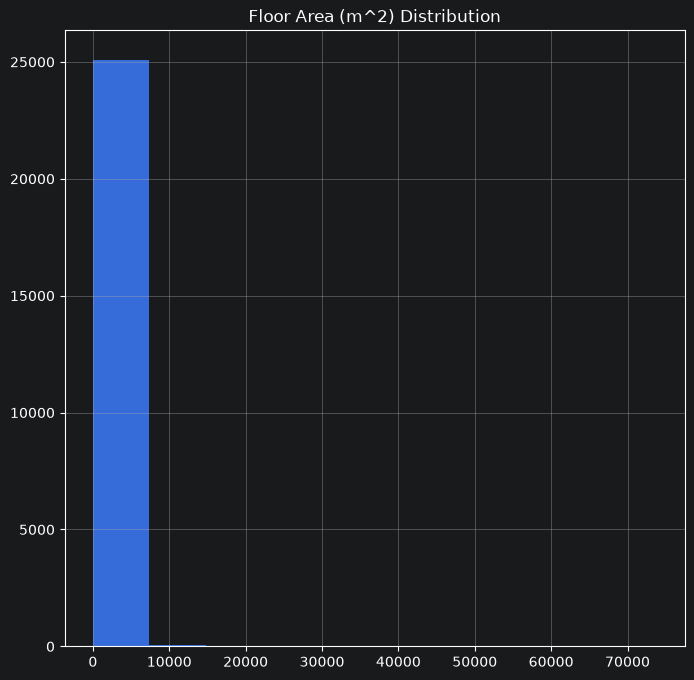

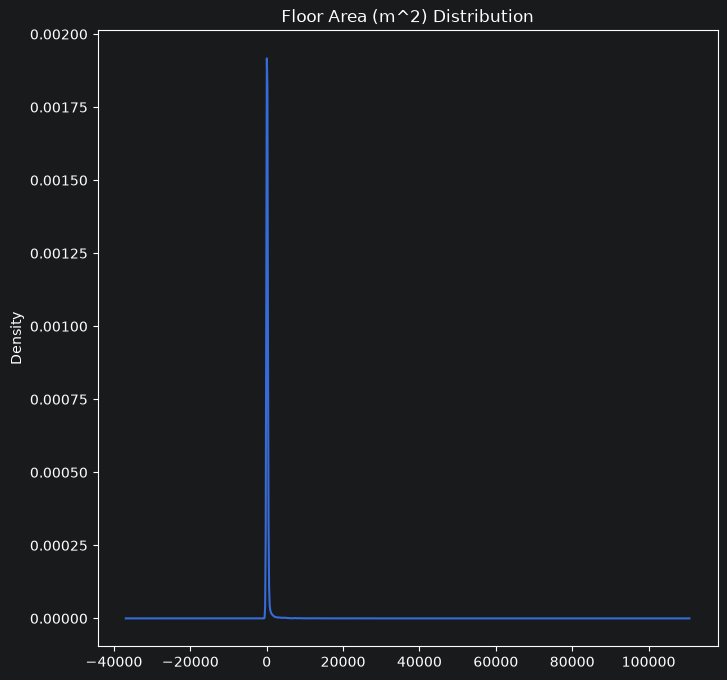

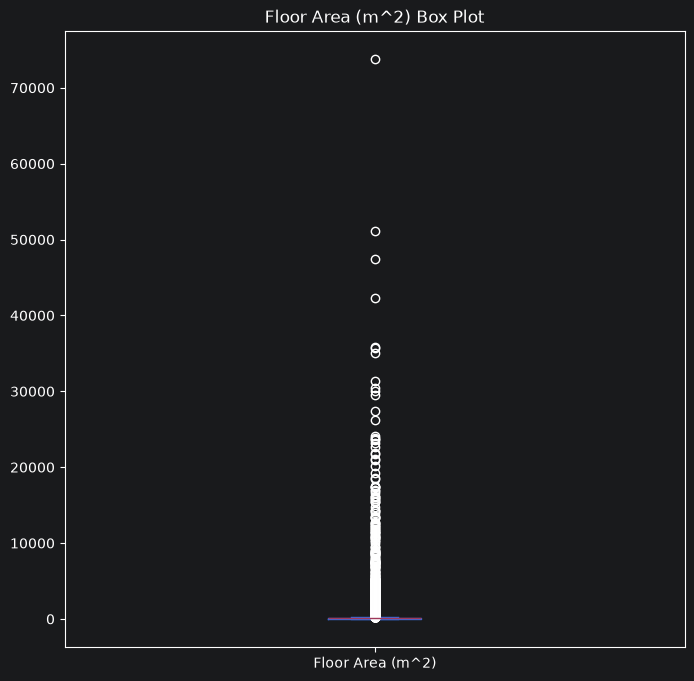

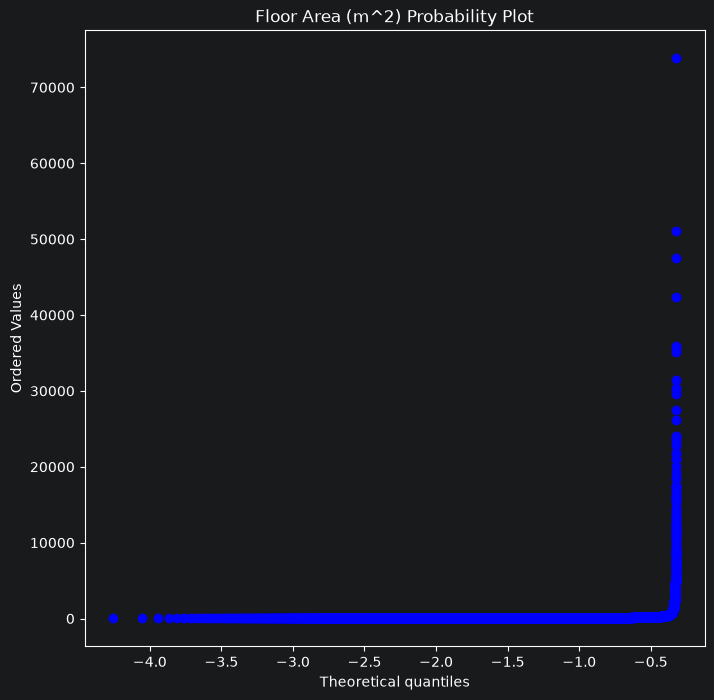

Minimum Floor Area (m^2): 3.0
Skew: -0.14
Kurtosis: 1.92
BoxCox Lambda: -0.33
Normal Test (Z-Score, P-Value): 1190.3333, 0.0000
p=0.0000: Data ostensibly does NOT have Gaussian distribution
Jarque-Bera Test (Z-Score, P-Value): 3944.0985, 0.0000
p=0.0000: Data ostensibly does NOT have Gaussian distribution


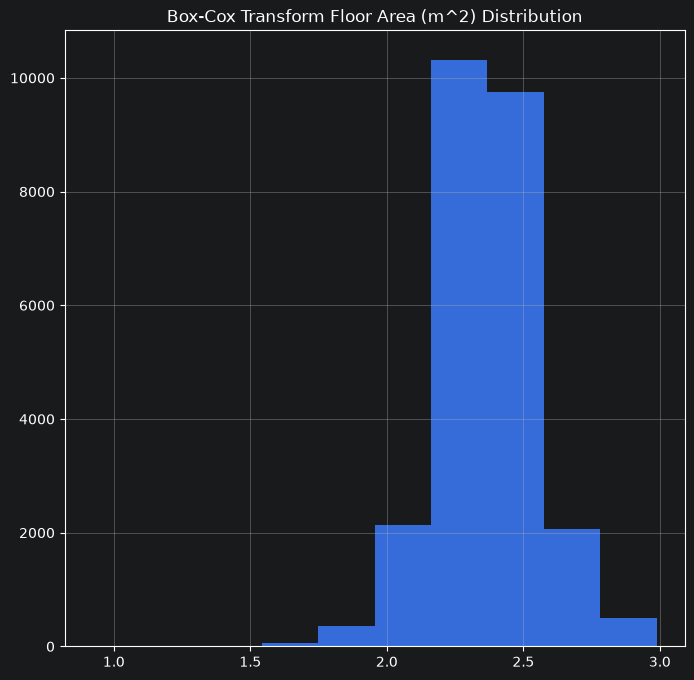

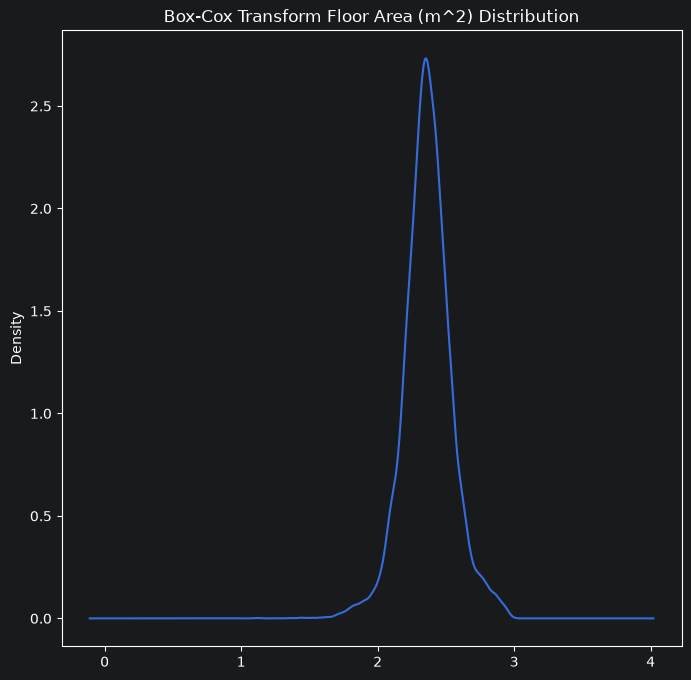

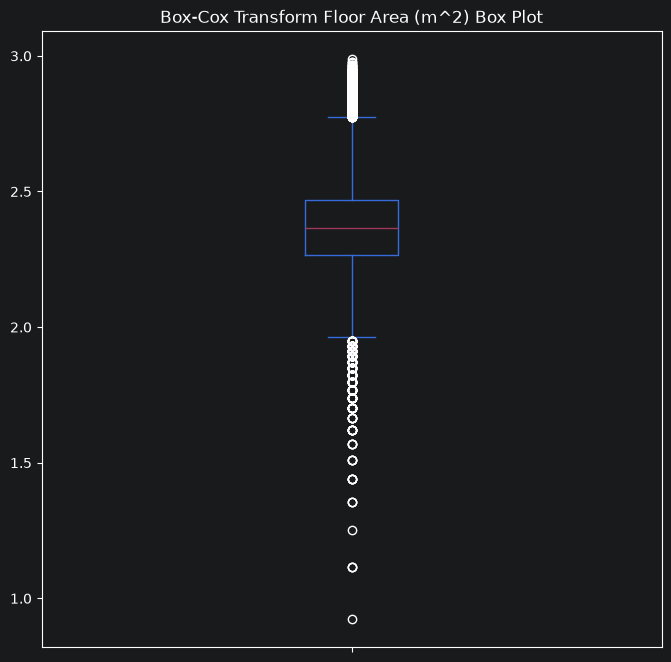

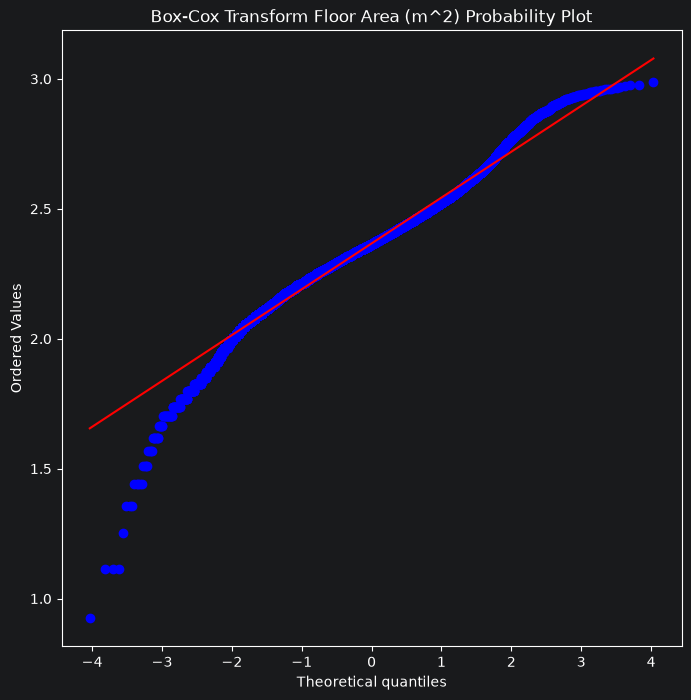

In [9]:
# Reassign floor area as transformed with box-cox for Gaussian-like distribution
x_train["Floor Area (m^2)"] = continuous_data_analysis(x_train.copy(deep=True))

The dataset contains one continuous feature which is positive and unbounded in nature as it represents the floor area of the property in square metres - it is also a highly sparse feature, retrieved from a joined dataset for the environmental efficiency of the property via another dataset that facilitates matching the UPRN by location.

Normaltest and Jarque-Bera were employed to evaluate the distribution by skewness and kurtosis, for comparison to a Gaussian distribution which will enable a wider selection of downstream models. These tests were chosen due to their robustness with a high sample count.

Although both tests fail to reject the null hypothesis after transformation (and therefore, it is not a normal distribution), visual inspection shows that for the purposes of this project, the distribution is satisfactory: the values only diverge at the outliers. Skewness is close to zero (-0.14), but the heavily left-tailed distribution leads to slightly abnormal kurtosis of 1.92 (lower than expected 3.0 for a perfect Gaussian distribution).

Organisation Entity
26      5603
382     9706
90     52032
dtype: int64

Development Classification
                                                                             52917
http://id.esd.org.uk/service/1736                                              473
http://id.esd.org.uk/service/1739                                              437
http://id.esd.org.uk/service/508                                              1448
http://opendatacommunities.org/def/concept/planning/application/6000/6001       95
http://opendatacommunities.org/def/concept/planning/application/6000/6002       17
http://opendatacommunities.org/def/concept/planning/application/6000/6003       22
http://opendatacommunities.org/def/concept/planning/application/6000/6004        6
http://opendatacommunities.org/def/concept/planning/application/6000/6006       63
http://opendatacommunities.org/def/concept/planning/application/6000/6007      990
http://opendatacommunities.org/def/concept/planning/application/6000/6

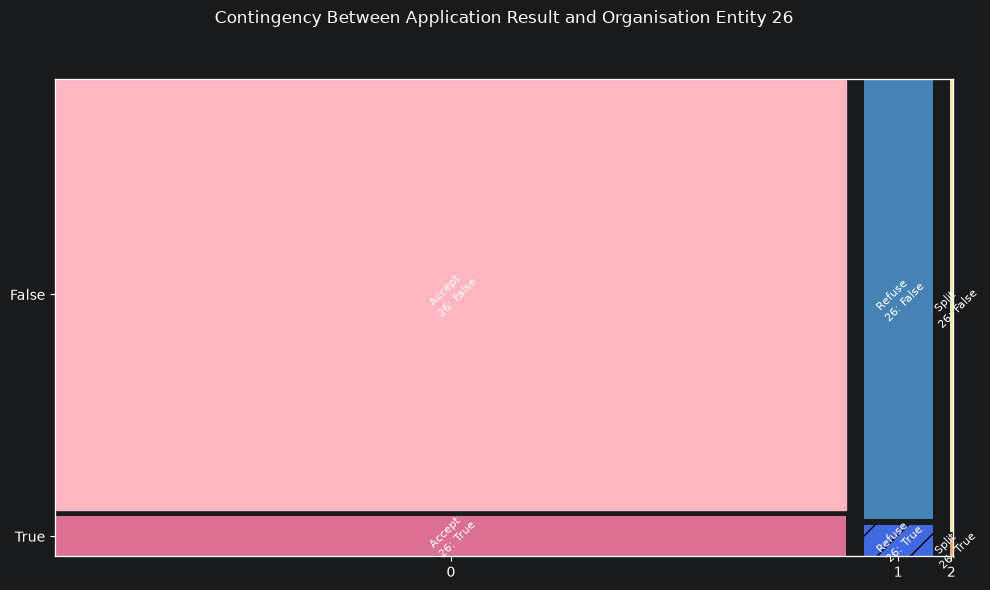

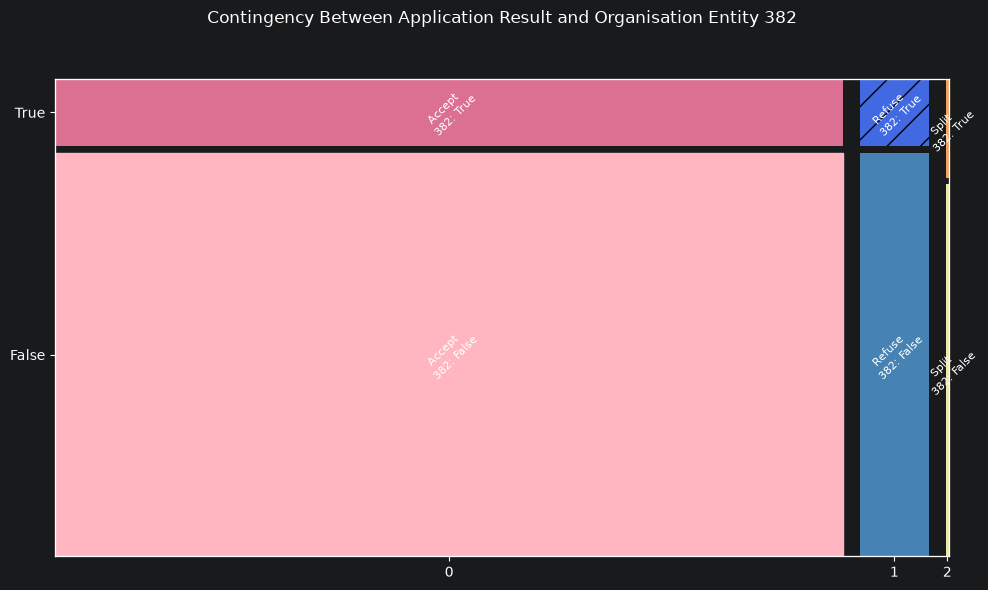

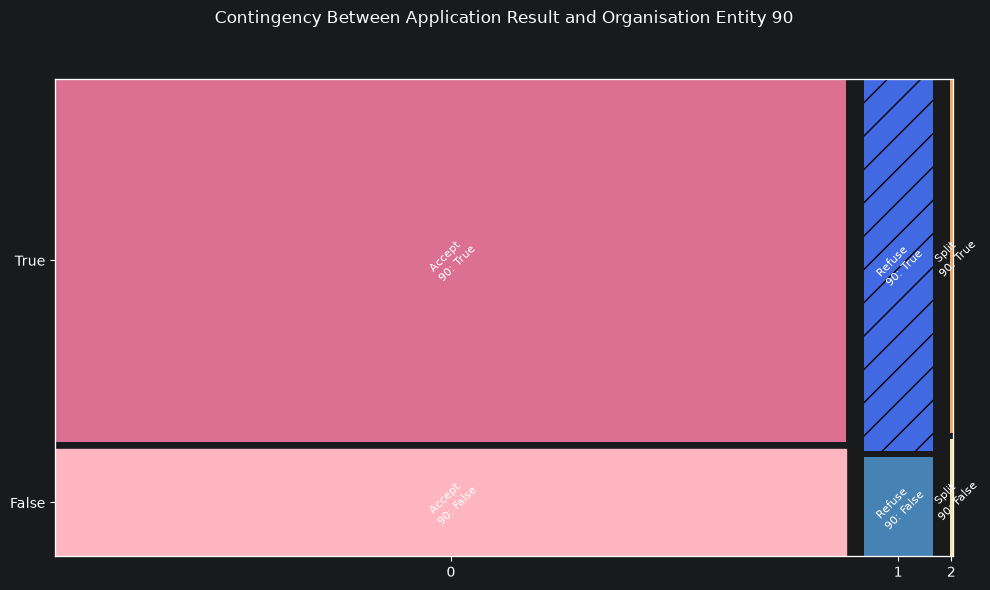

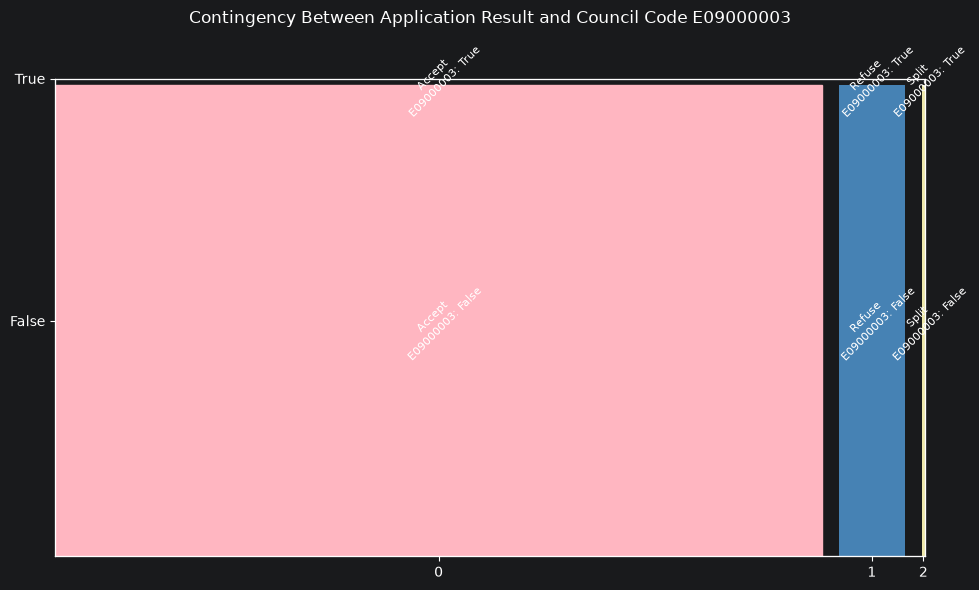

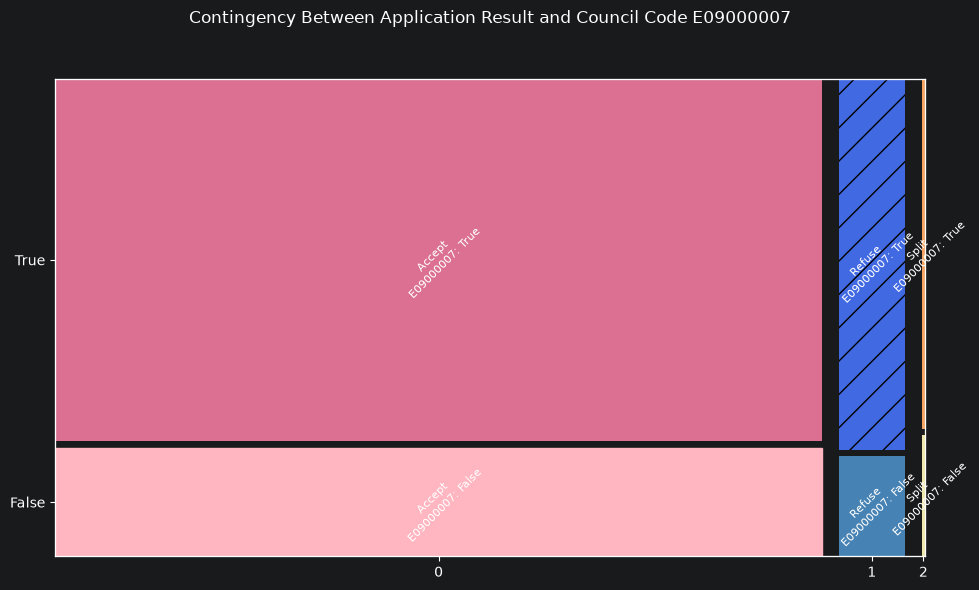

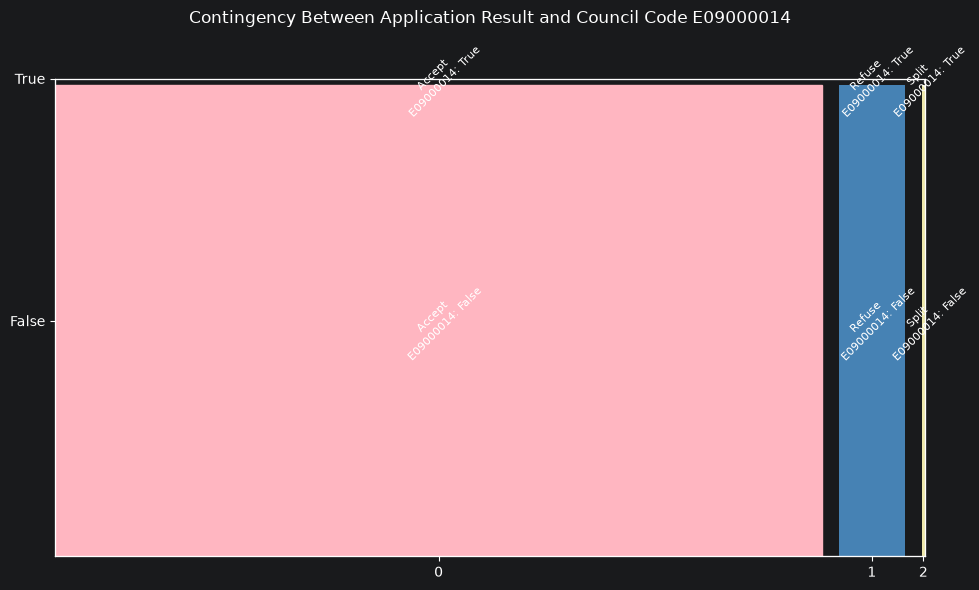

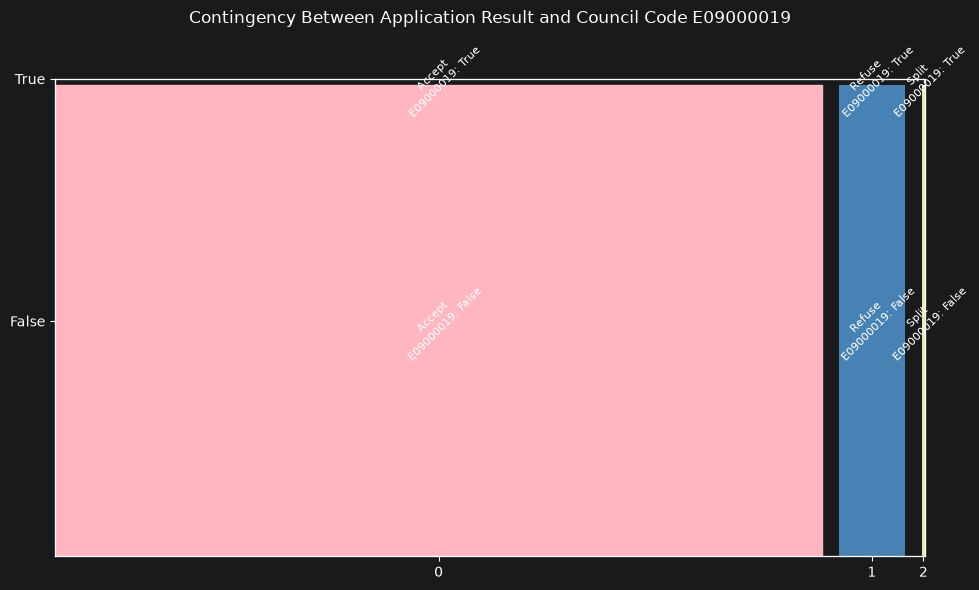

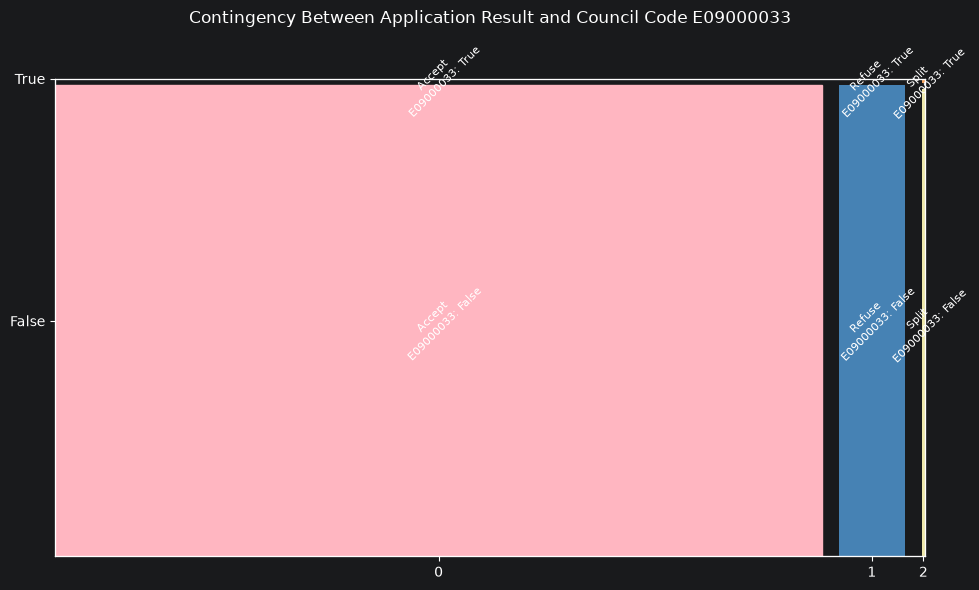

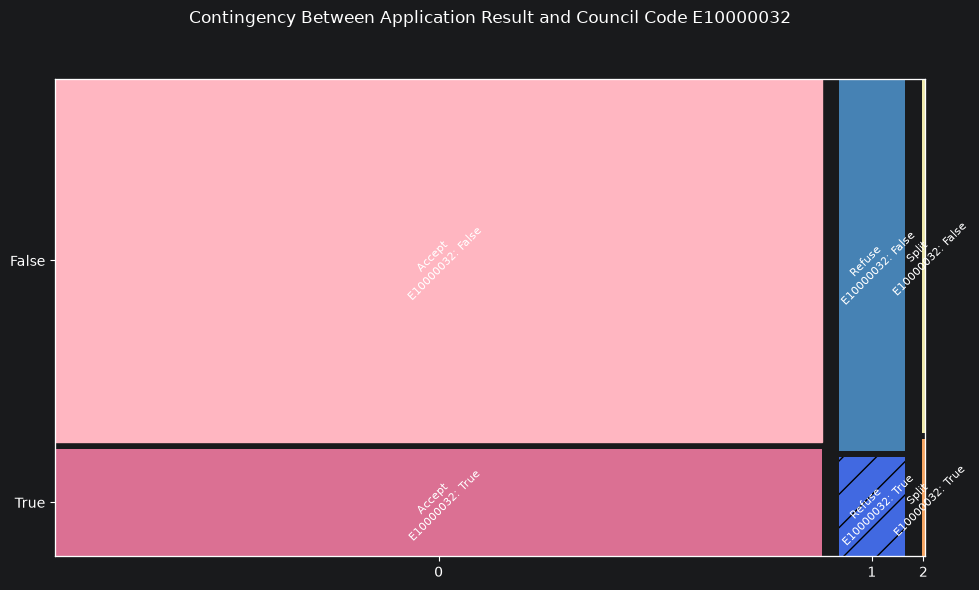

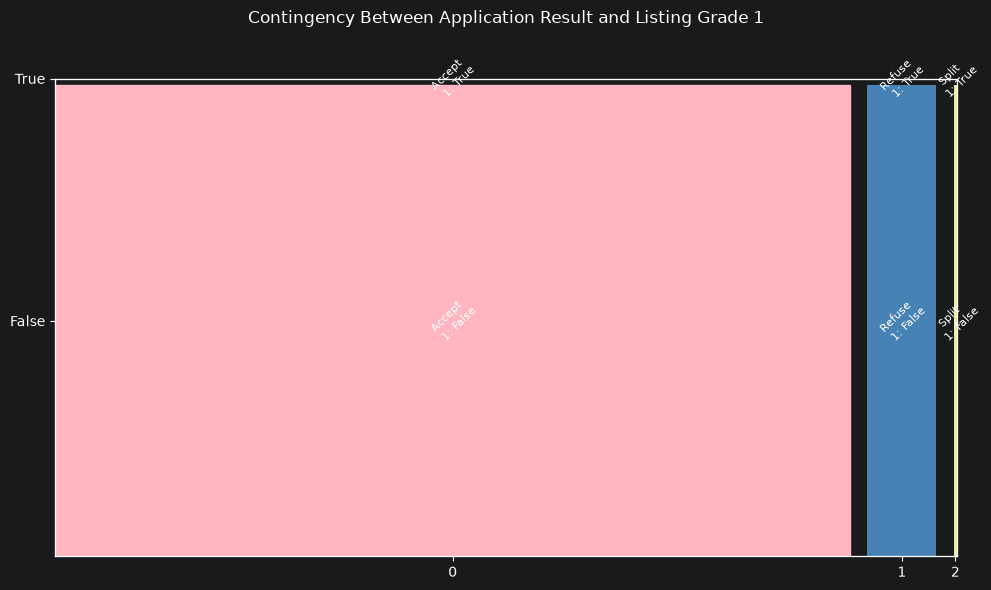

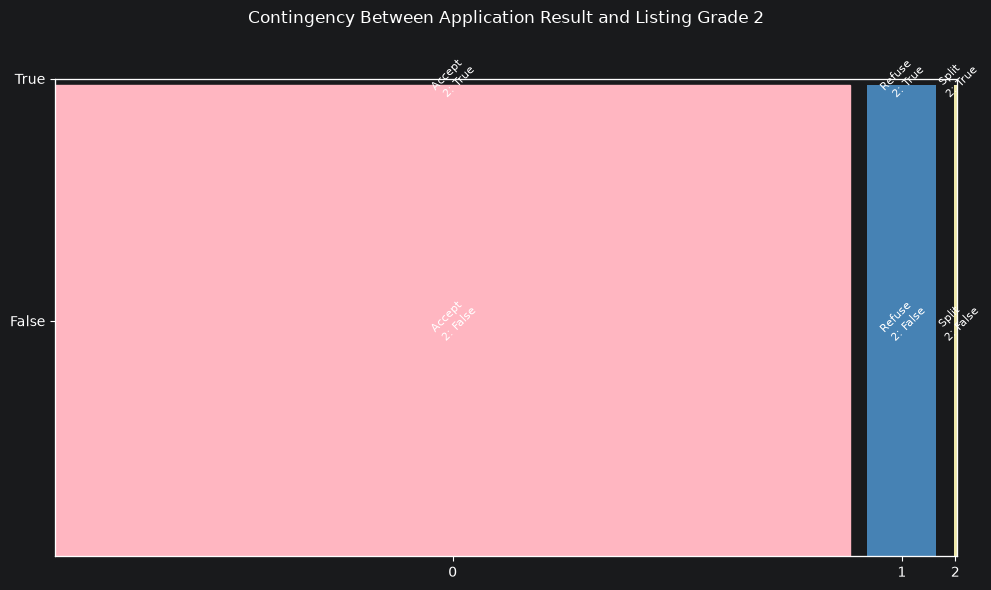

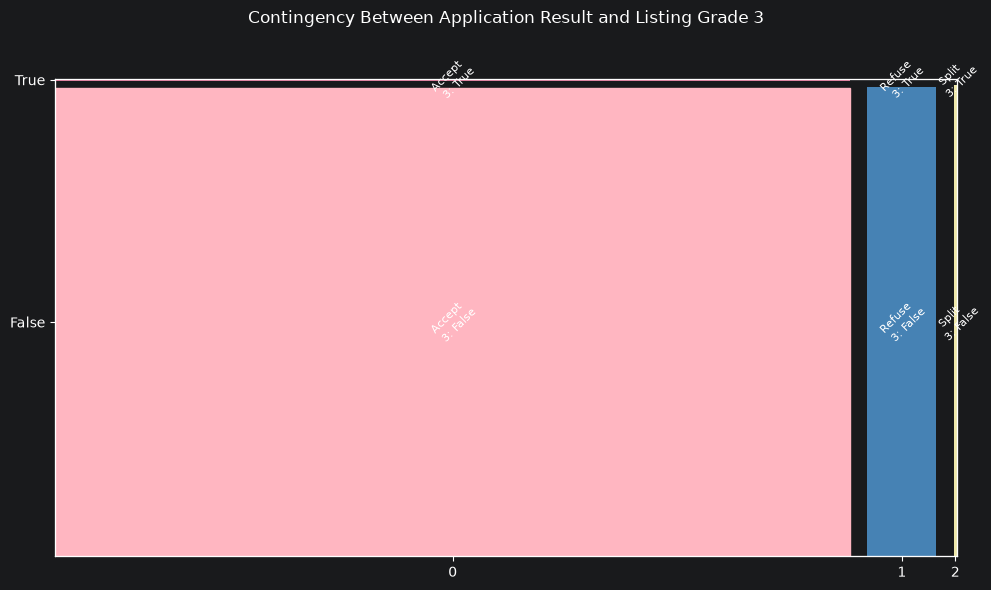

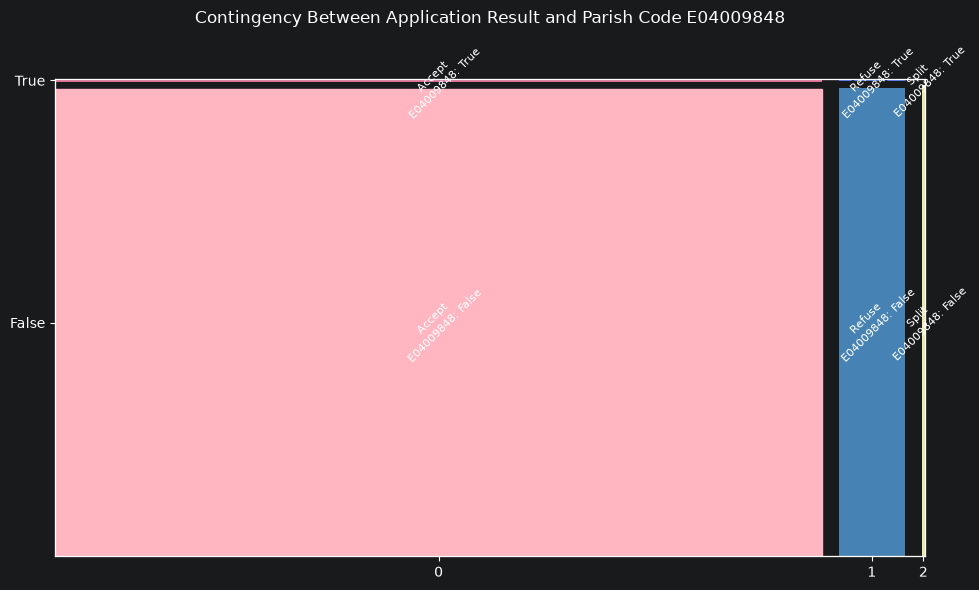

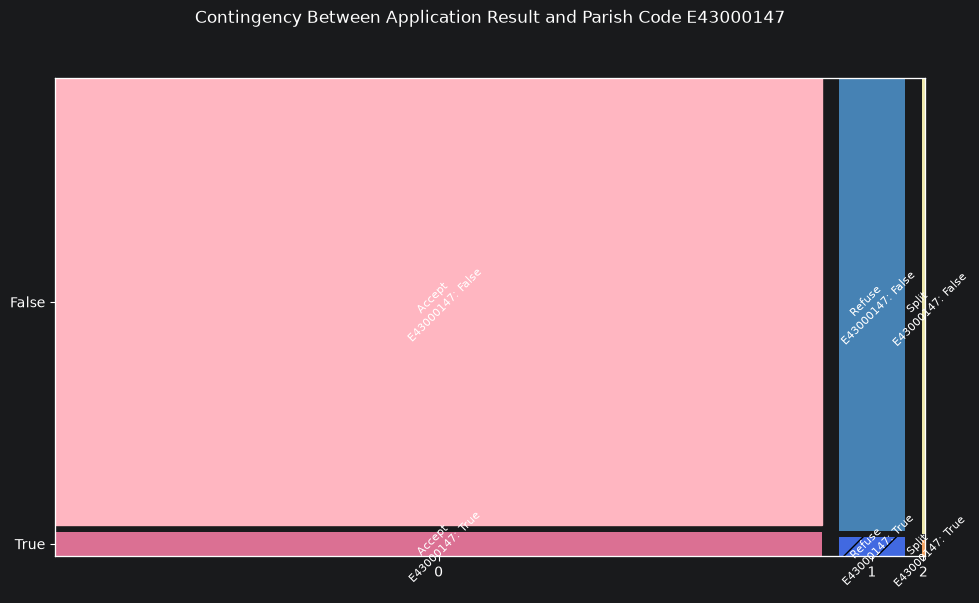

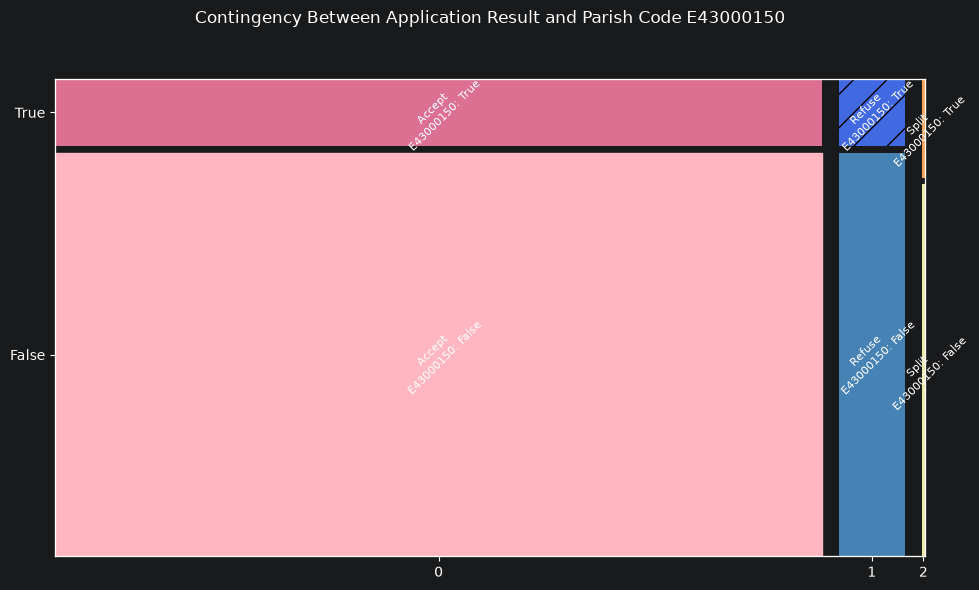

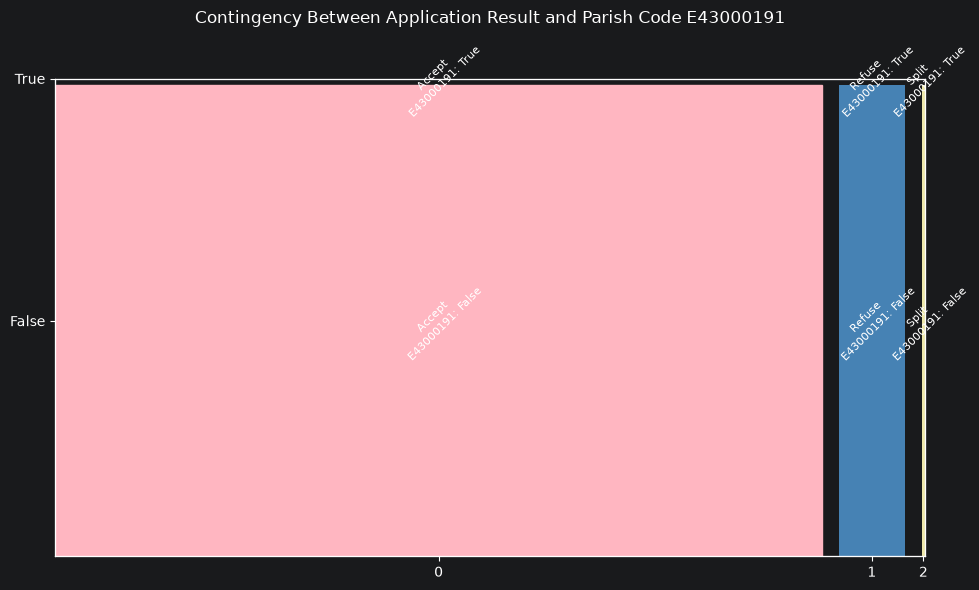

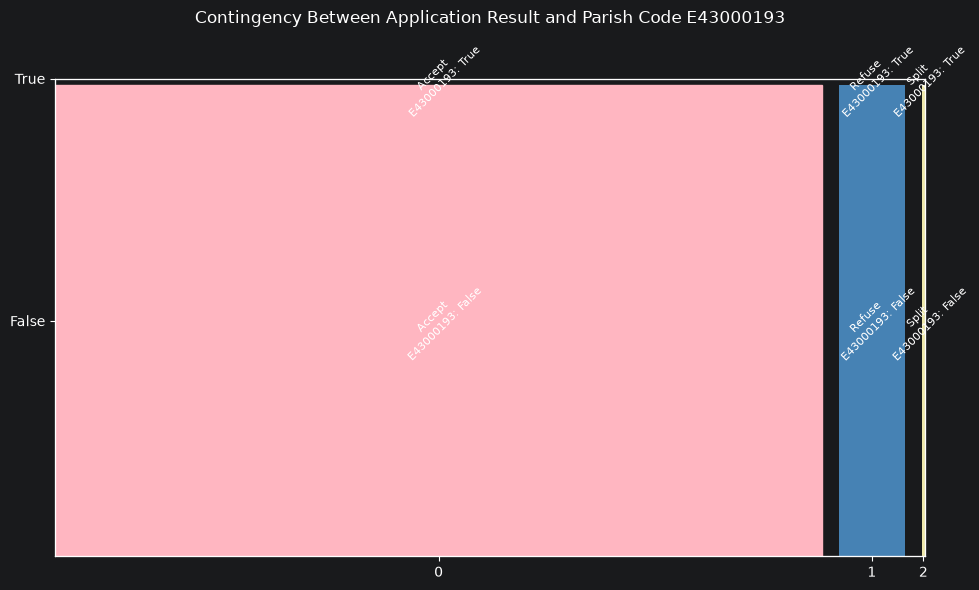

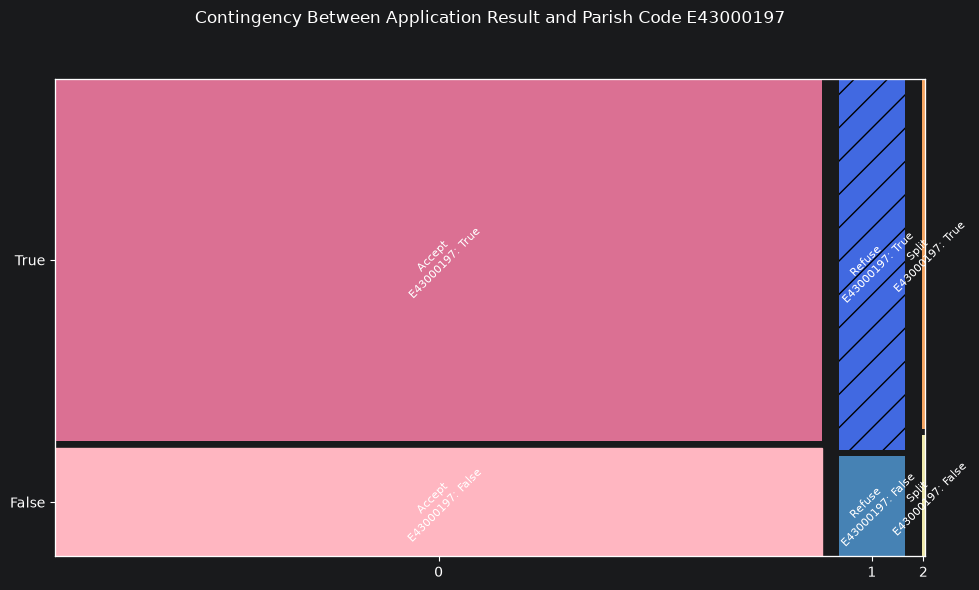

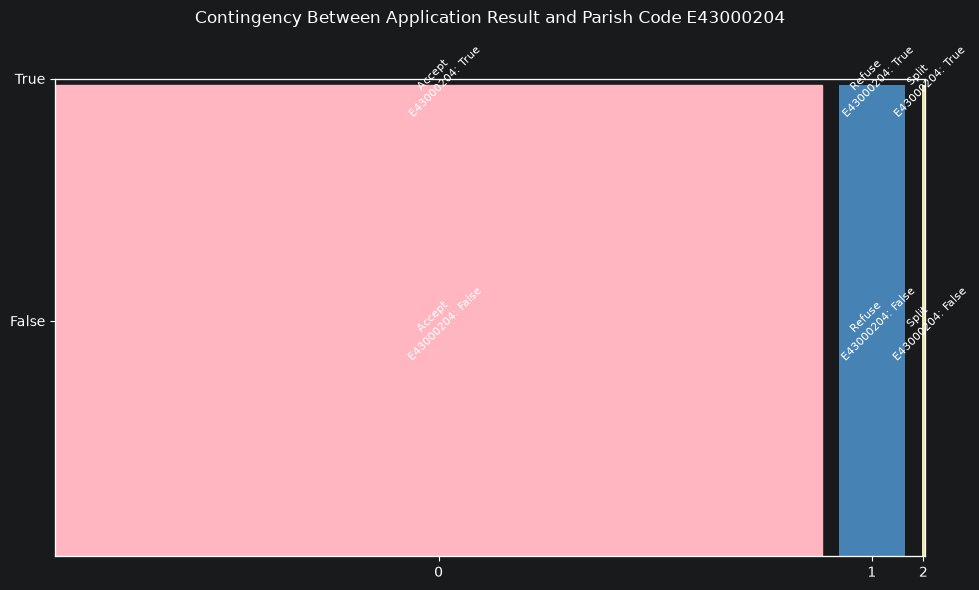

In [10]:
x_train, y_train = discrete_data_analysis(x_train.copy(deep=True), y_train.copy(deep=True))

A large number of categories have a high degree of cardinality, therefore target encoding is utilised.

Alternatives such as one-hot encoding and feature hashing were considered but not employed due to their anticipated impact on increasing dimensionality and on model choice.

| Category Feature           | Encoding Choice |
|----------------------------|-----------------|
| Organisation Entity        | Dummy Encoding  |
| Council Code               | Dummy Encoding  |
| Listing Grade              | Dummy Encoding  |
| Parish Code                | Dummy Encoding  |
| LSOA Code                  | Target Encoding |
| Development Classification | Target Encoding |
| Property Type              | Target Encoding |

Furthermore, the mosaic plots demonstrate the very imbalanced distribution of the target variable which needs to be rebalanced using SMOTENC (- the dataset comprises categorical and numeric data).


In [11]:
text_transform_dfs = text_data_analysis(x_train.copy(deep=True), y_train.copy(deep=True))

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2698.87it/s]


Count Vectorizer Shape: (67341, 273)
TF-IDF Vectorizer Shape: (67341, 273)
sBERT Embeddings Shape: (67341, 385)
Vectorizer Vocabulary Difference: 0


Index(['Description', 'Development Classification',
       'Decision Date Year Of Transfer', 'Decision Date Quarter Of Transfer',
       'LSOA Code', 'IMD Rank', 'IMD Decile', 'In Conservation Area',
       'Geohazards Collapsible Deposits Susceptibility',
       'Geohazards Running Sand Susceptibility',
       'Geohazards Shrink Swell Susceptibility',
       'Geohazards Soluble Rocks Susceptibility', 'In Flood Zone',
       'Property Type', 'Floor Area (m^2)', 'Is Domestic',
       'Near Brownfield Site', 'In Built Up Area', 'In Article 4 Area',
       'Organisation Entity_26', 'Organisation Entity_382',
       'Organisation Entity_90', 'Council Code_E09000003',
       'Council Code_E09000007', 'Council Code_E09000014',
       'Council Code_E09000019', 'Council Code_E09000033',
       'Council Code_E10000032', 'Listing Grade_1', 'Listing Grade_2',
       'Listing Grade_3', 'Parish Code_E04009848', 'Parish Code_E43000147',
       'Parish Code_E43000150', 'Parish Code_E43000191',
      

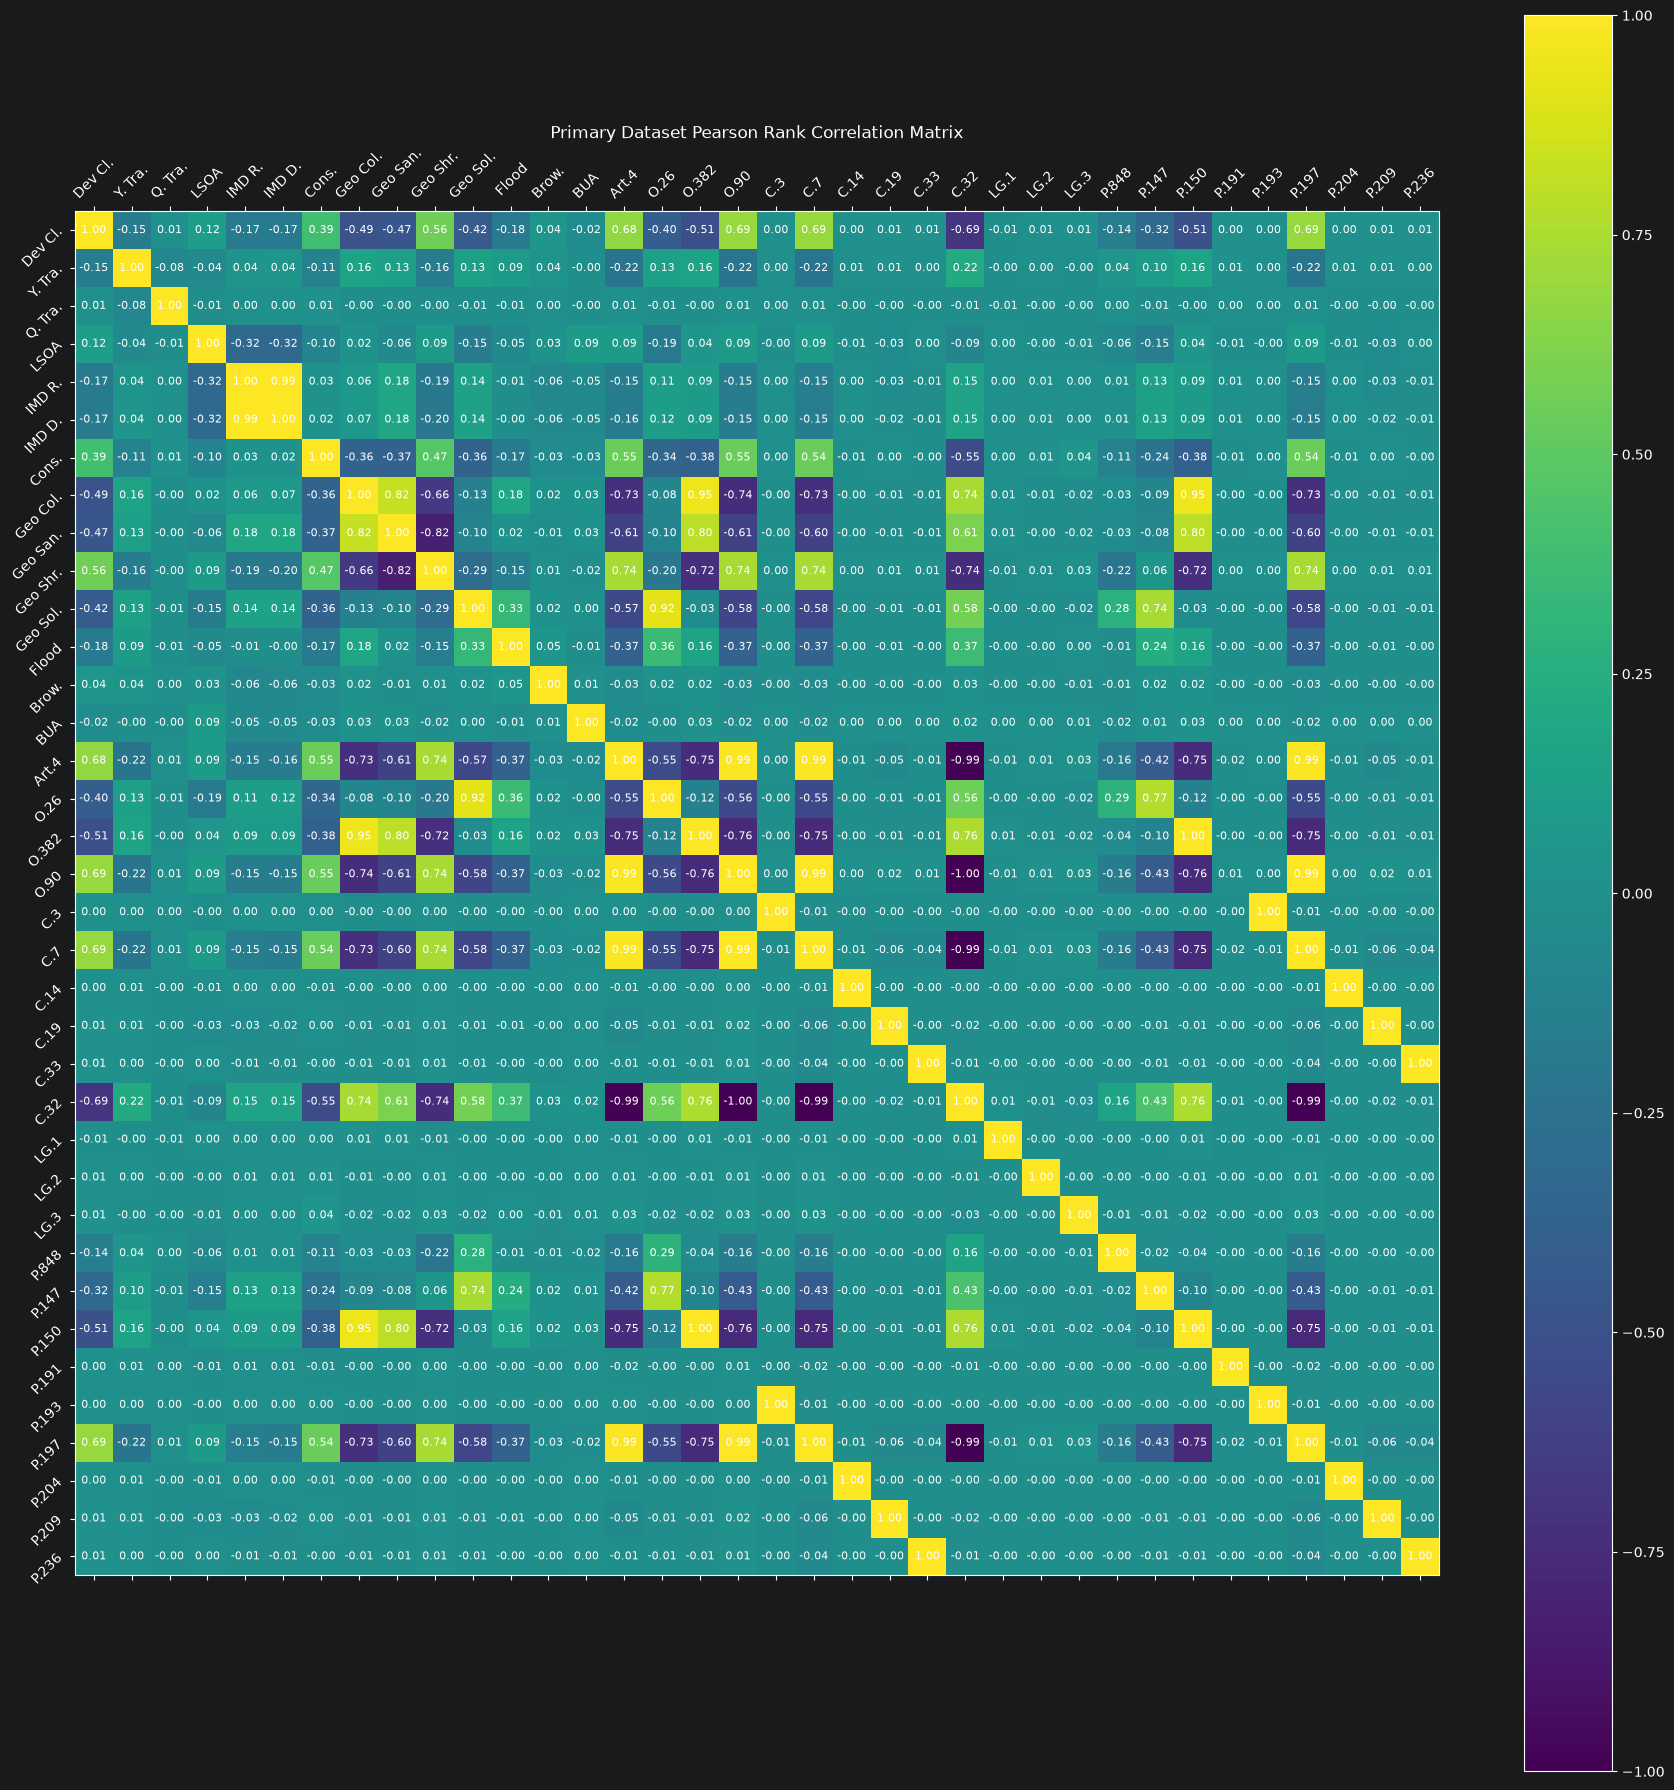

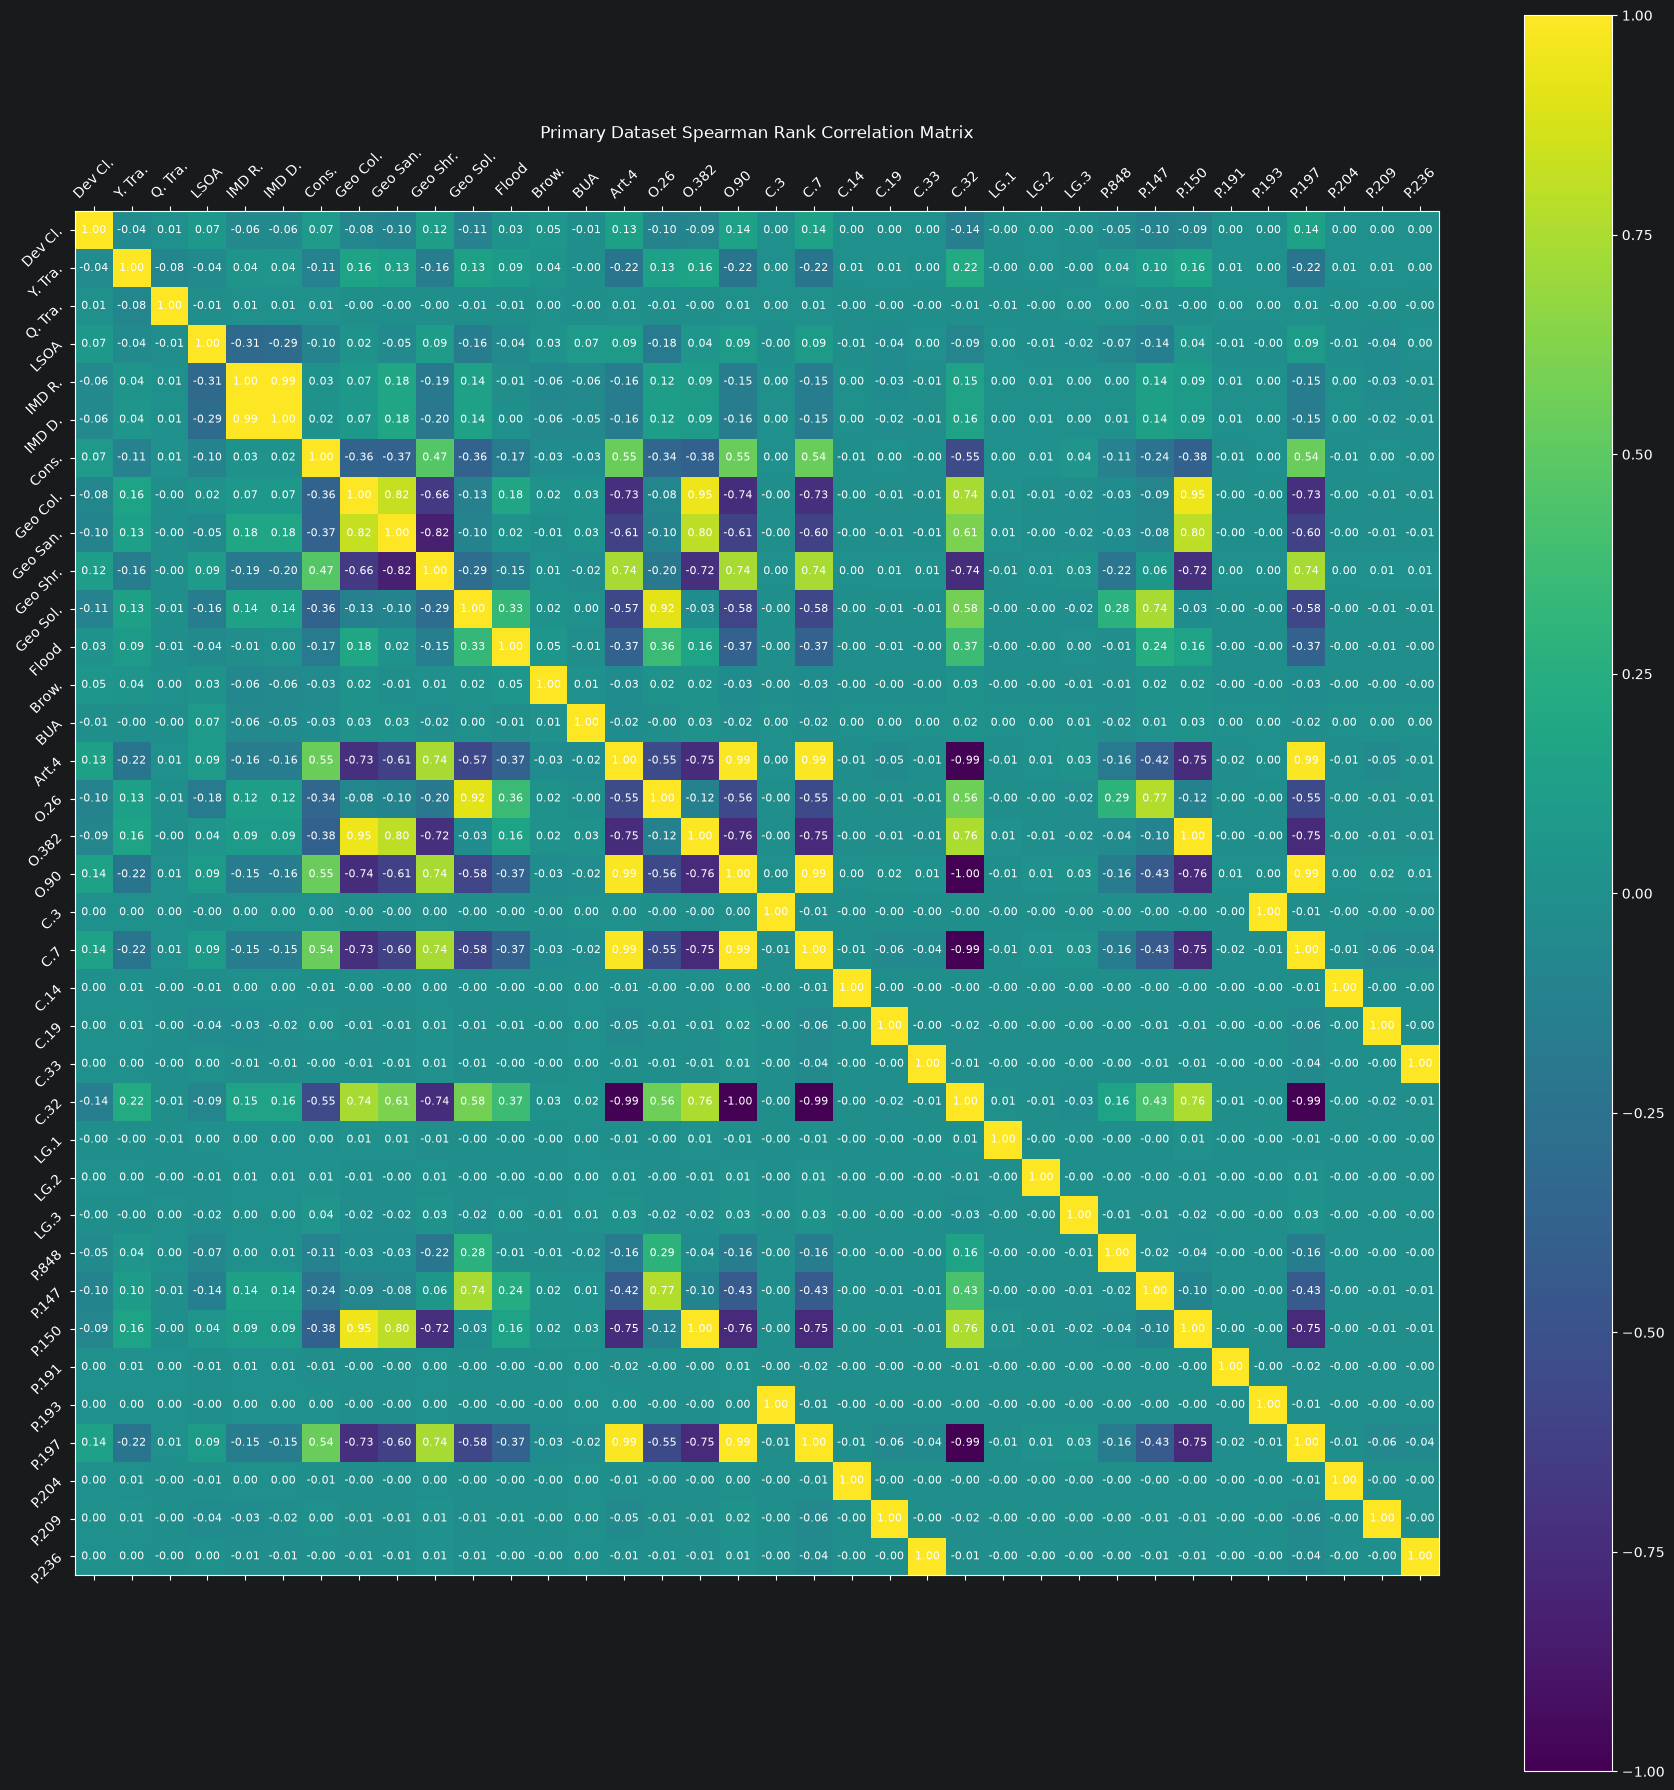

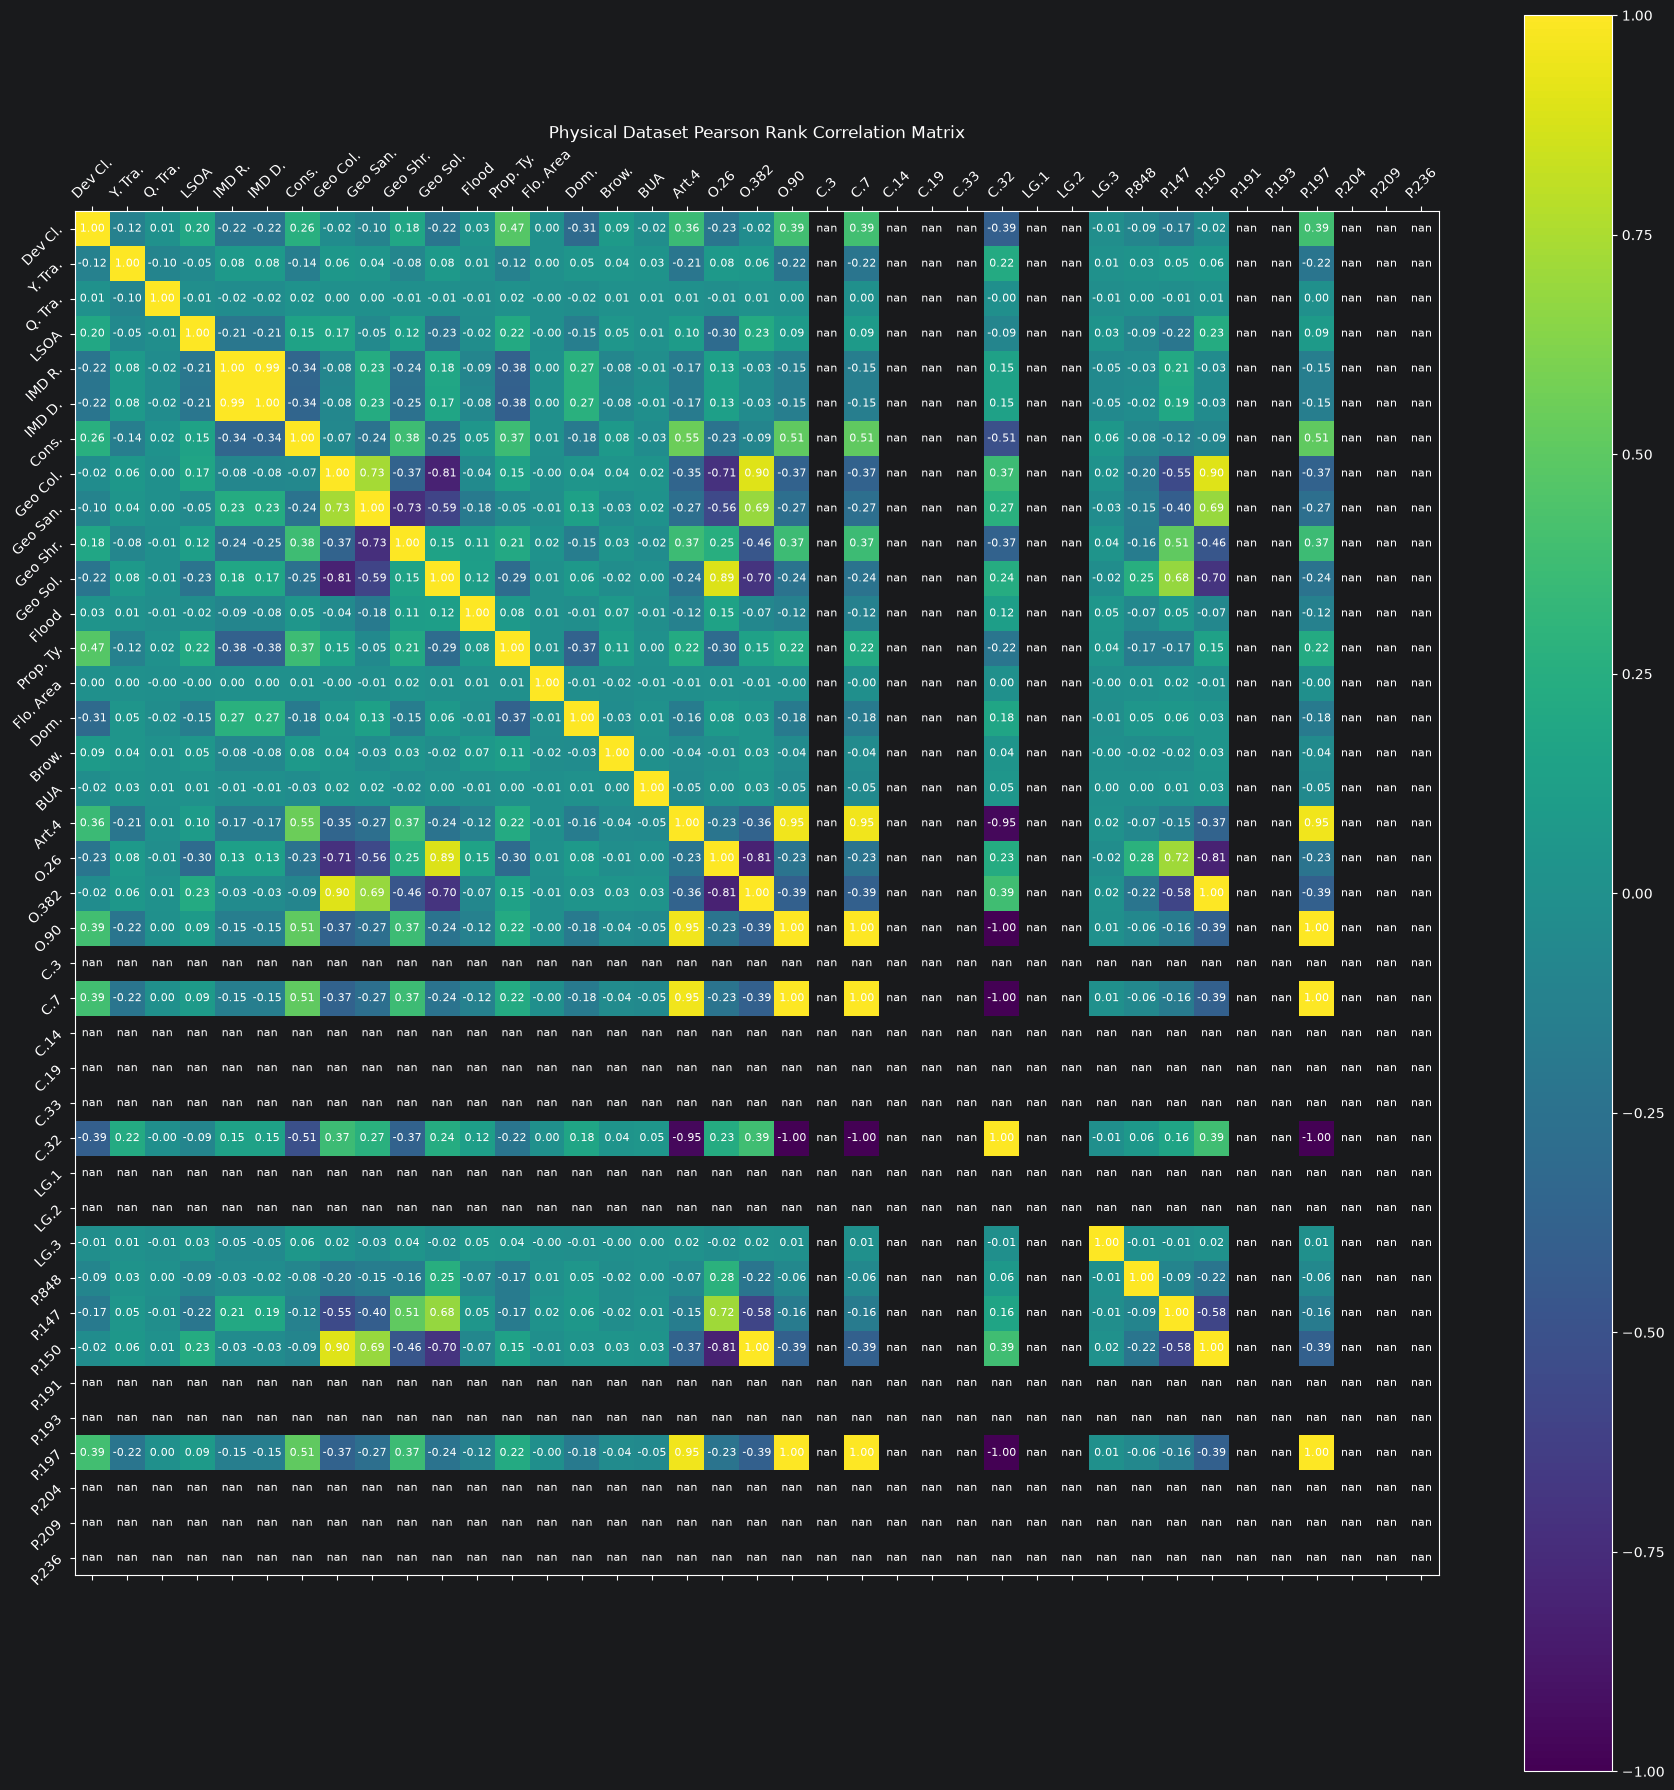

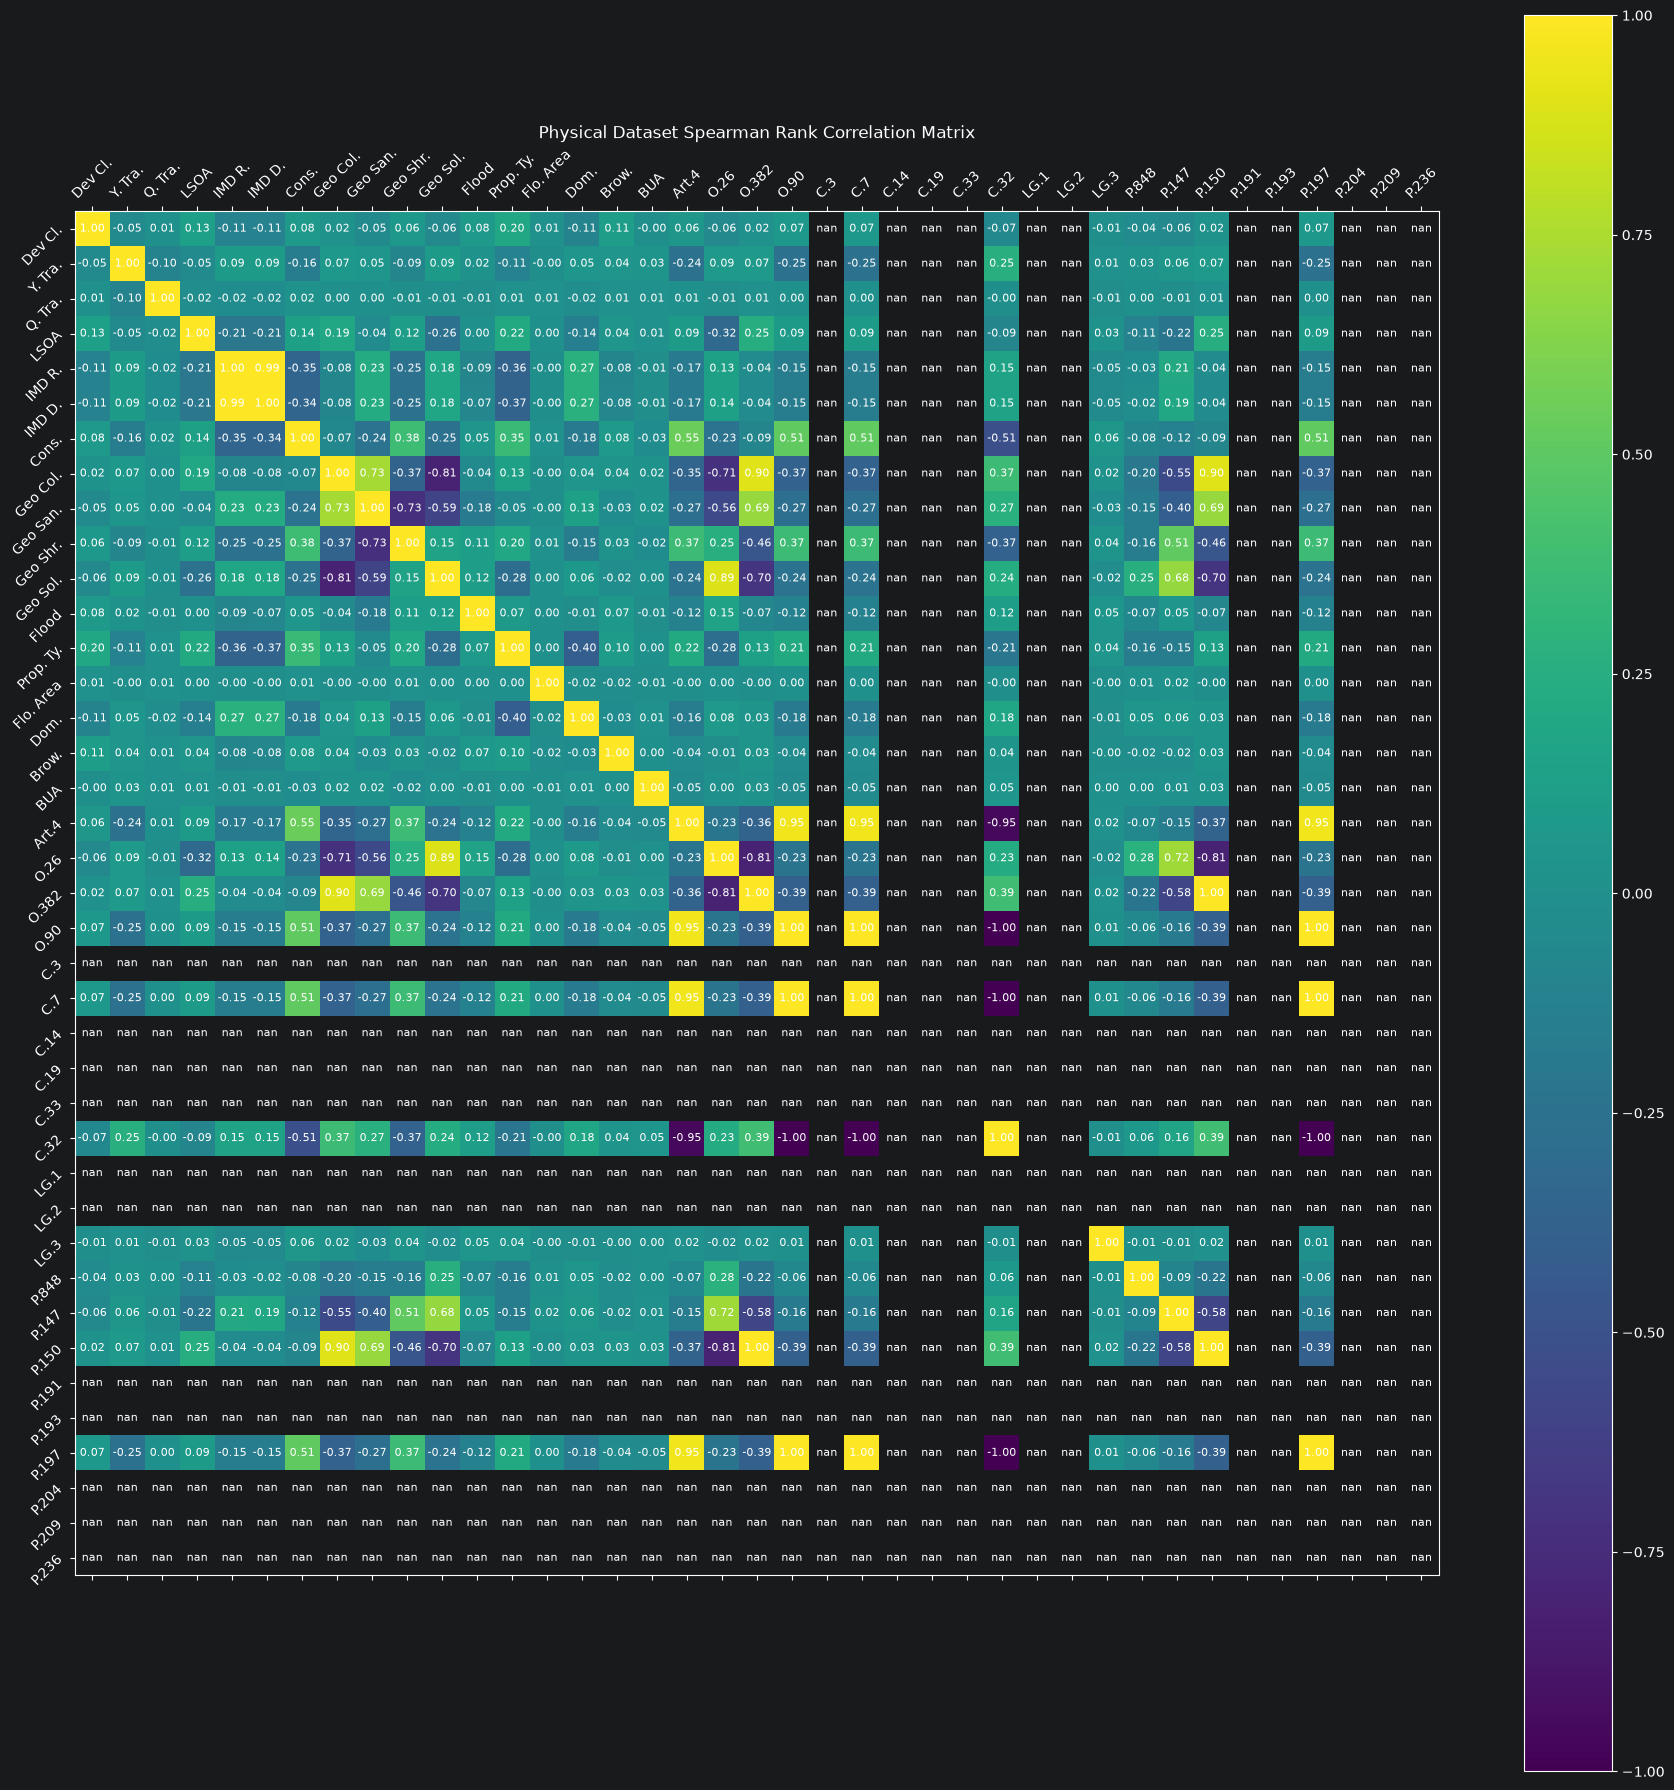

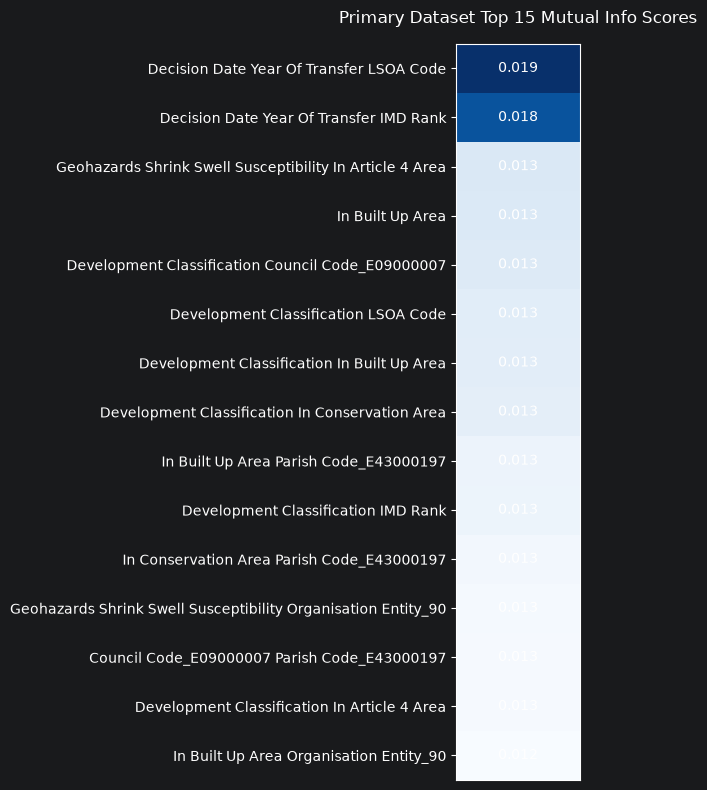

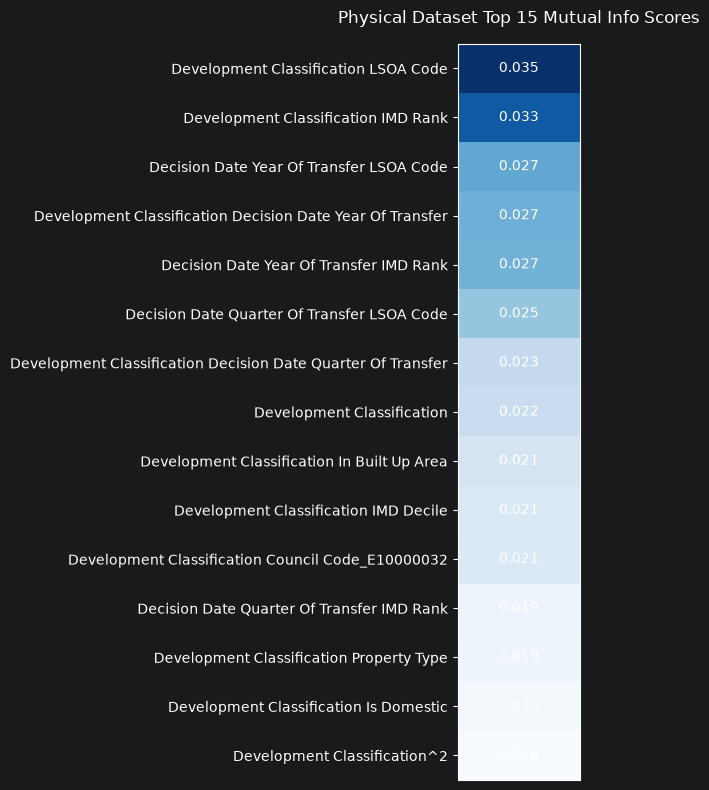

Count Vectorizer Correlations:
Inferred Planning Decision    1.000000
erection                      0.073568
c3                            0.072532
mansard                       0.071504
bedroom                       0.064595
class                         0.063936
on                            0.059635
display                       0.050946
installation                  0.050343
dwelling                      0.049911
create                        0.046369
roof                          0.044316
retrospective                 0.043010
change                        0.042306
first                         0.042225
terrace                       0.041942
with                          0.041868
of                            0.041603
bed                           0.038622
tpo                           0.038495
additional                    0.038058
second                        0.037720
public                        0.037377
floor                         0.036974
contained                     0.0

In [19]:
correlation_analysis(x_train, y_train, text_transform_dfs)

In [13]:
# Drop categorical columns with no explanatory value as no, or insignificant, split:
x_train.drop(columns=[
    "Entry Date Year Of Transfer",
    "Entry Date Quarter Of Transfer",
    "Geohazards Compressible Ground Susceptibility",
    "Geohazards Landslides Susceptibility",

    "In Ancient Woodlands",
    "In Green Belt",
    "In Special Area of Conservation"
], inplace=True)

KeyError: "['Entry Date Year Of Transfer', 'Entry Date Quarter Of Transfer', 'Geohazards Compressible Ground Susceptibility', 'Geohazards Landslides Susceptibility', 'In Ancient Woodlands', 'In Green Belt', 'In Special Area of Conservation'] not found in axis"